In [ ]:
import numpy as np

### random.normal setting
* loc = mean
* scale = standard devation(SD)

In [32]:
x = np.arange(1, 31)
noise = np.random.normal(loc = 0, scale = 0.4, size = x.shape)
y = x + noise

x = x.reshape(-1, 1)
y = y.reshape(-1, 1)

print(y)


[[ 0.98287454]
 [ 1.9703319 ]
 [ 2.83023936]
 [ 4.09046733]
 [ 5.46560126]
 [ 5.18959231]
 [ 6.18989366]
 [ 8.60751994]
 [ 9.80692627]
 [10.50379559]
 [11.37317772]
 [11.50142137]
 [13.08152886]
 [13.83259149]
 [14.05543464]
 [15.96826937]
 [17.64657618]
 [18.58714286]
 [18.60638075]
 [20.00604153]
 [21.65053655]
 [21.42589966]
 [22.43197296]
 [23.99225957]
 [25.58876295]
 [26.02359426]
 [26.67320057]
 [28.3043932 ]
 [28.97896341]
 [30.42303017]]


In [38]:
x = np.arange(1, 31)
noise = np.random.normal(loc = 0, scale = 0.5, size = x.shape)
y = x + noise

x = x.reshape(-1, 1)
y = y.reshape(-1, 1)

# print(y)


weight = 0.0
bias = 0.0
learning_rate = 0.005

# setting epoch

for epoch in range(10000):
    y_hat = weight * x + bias
    # MSE
    cost = ((y - y_hat)**2).mean()

    weight = weight - learning_rate * ((y_hat - y) * x).mean()
    bias = bias - learning_rate * ((y_hat - y)).mean()
    if (epoch + 1) <= 100:
        print(f"Epoch : {epoch + 1:4d}, Weight = {weight:.3f}, Bias : {bias:.3f}, Cost : {cost:.3f}")

Epoch :    1, Weight = 1.573, Bias : 0.077, Cost : 314.182
Epoch :    2, Weight = 0.661, Bias : 0.032, Cost : 105.726
Epoch :    3, Weight = 1.190, Bias : 0.058, Cost : 35.686
Epoch :    4, Weight = 0.883, Bias : 0.043, Cost : 12.154
Epoch :    5, Weight = 1.061, Bias : 0.052, Cost : 4.247
Epoch :    6, Weight = 0.958, Bias : 0.047, Cost : 1.590
Epoch :    7, Weight = 1.018, Bias : 0.050, Cost : 0.698
Epoch :    8, Weight = 0.983, Bias : 0.048, Cost : 0.398
Epoch :    9, Weight = 1.003, Bias : 0.049, Cost : 0.297
Epoch :   10, Weight = 0.991, Bias : 0.048, Cost : 0.263
Epoch :   11, Weight = 0.998, Bias : 0.049, Cost : 0.252
Epoch :   12, Weight = 0.994, Bias : 0.048, Cost : 0.248
Epoch :   13, Weight = 0.996, Bias : 0.048, Cost : 0.247
Epoch :   14, Weight = 0.995, Bias : 0.048, Cost : 0.246
Epoch :   15, Weight = 0.996, Bias : 0.048, Cost : 0.246
Epoch :   16, Weight = 0.996, Bias : 0.048, Cost : 0.246
Epoch :   17, Weight = 0.996, Bias : 0.048, Cost : 0.246
Epoch :   18, Weight = 0.

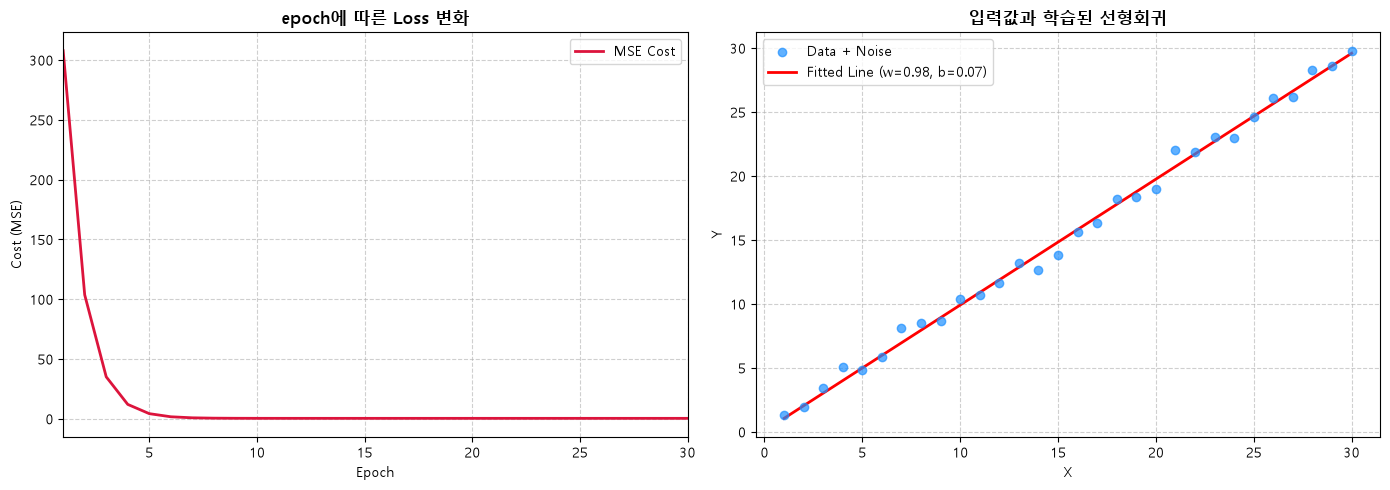

In [42]:
import numpy as np
import matplotlib.pyplot as plt

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False  # 마이너스(-) 기호 깨짐 방지

# 1. 데이터 생성 (seed 고정)
np.random.seed(42)
x = np.arange(1, 31)
noise = np.random.normal(loc=0, scale=0.7, size=x.shape)
y = x + noise

x = x.reshape(-1, 1)
y = y.reshape(-1, 1)

# 2. 파라미터 및 기록용 리스트 초기화
weight = 0.0
bias = 0.0
learning_rate = 0.005
epochs = 100

cost_history = []
weight_history = []
bias_history = []

# 3. 학습 진행
for epoch in range(epochs):
    y_hat = weight * x + bias
    cost = ((y - y_hat) ** 2).mean()

    # 기록 저장
    cost_history.append(cost)
    weight_history.append(weight)
    bias_history.append(bias)

    # 경사하강법 갱신
    weight = weight - learning_rate * ((y_hat - y) * x).mean()
    bias = bias - learning_rate * (y_hat - y).mean()

# ---------------------------------------------------------
# 4. 시각화 (Subplots 활용)
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (1) 왼쪽 그래프: Epoch에 따른 Cost 변화 (손실 감소)
axes[0].plot(range(1, epochs + 1), cost_history, color='crimson', linewidth=2, label='MSE Cost')
axes[0].set_title('epoch에 따른 Loss 변화', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=10)
axes[0].set_ylabel('Cost (MSE)', fontsize=10)
axes[0].set_xlim(1, 30)  # 초반 30 Epoch에 수렴이 몰려있으므로 범위를 지정하여 확대
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# (2) 오른쪽 그래프: 최종 선형 회귀 직선과 실제 데이터 비교
axes[1].scatter(x, y, color='dodgerblue', alpha=0.7, label='Data + Noise', zorder=3)
axes[1].plot(x, weight * x + bias, color='red', linewidth=2, 
             label=f'Fitted Line (w={weight:.2f}, b={bias:.2f})')
axes[1].set_title('입력값과 학습된 선형회귀', fontsize=12, fontweight='bold')
axes[1].set_xlabel('X', fontsize=10)
axes[1].set_ylabel('Y', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

## Linear Regression : Pytorch
---
같은 과정을 Pytorch를 이용해서 진행

In [1]:
import torch
from torch import optim

In [2]:
x = torch.arange(1, 31, dtype = torch.float32).reshape(-1, 1)
noise = torch.randn(x.shape) * 0.6 #mean = 0, std = 0.5
y = x + noise




torch.zeros 를 통해서 기존의 torch.FloatTensor([[0,0]])를 대체한다.
* requires_grad : True로 설정하면 모든 텐서에 대한 연산을 추적하며 역전파 메서드를 호출해 기울기를 계산하고 저장한다.

In [3]:
weight = torch.zeros(1, requires_grad = True)
bias = torch.zeros(1, requires_grad = True)
learning_rate = 0.01


optimizer = optim.SGD([weight ,bias], lr = learning_rate)

### Method 설명
---

* zero_grad() : 기존 기울기 비우기
* backward() : 새로 기울기 계산하기(weigth.grad, bias.grad 채우기)
* .step() : 가중치, 편향 실제로 한 걸음 이동하기

In [ ]:
for epoch in range(10000):
    hypothesis = x * weight + bias
    cost = torch.mean((hypothesis - y) ** 2)

    optimizer.zero_grad()
    cost.backward()
    optimizer.step()

    if (epoch + 1) % 1000 == 0:
        print(f"Epoch : {epoch}")
